# 01 – Exploratory Data Analysis
UCI Heart Disease (Cleveland, 303 patients). Data is produced by `python -m src.data`.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())

In [2]:
import pandas as pd
from src.data import CLEAN_PATH, TARGET, NUMERIC_FEATURES, CATEGORICAL_FEATURES
df = pd.read_csv(CLEAN_PATH)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1,1,145.0,233.0,1,2,150.0,0,2.3,3,0.0,6.0,0
1,67.0,1,4,160.0,286.0,0,2,108.0,1,1.5,2,3.0,3.0,1
2,67.0,1,4,120.0,229.0,0,2,129.0,1,2.6,2,2.0,7.0,1
3,37.0,1,3,130.0,250.0,0,0,187.0,0,3.5,3,0.0,3.0,0
4,41.0,0,2,130.0,204.0,0,2,172.0,0,1.4,1,0.0,3.0,0


## Data quality
Only `ca` (4) and `thal` (2) have missing values – they are imputed *inside* the model pipeline so the test folds never leak into the imputer.

In [3]:
df.info()
df.isna().sum()[lambda s: s > 0]

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    float64
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(7), int64(7)
memory usage: 33.3 KB


ca      4
thal    2
dtype: int64

In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## Class balance
~54% / 46% – mild imbalance, so plain accuracy is acceptable but we also track recall and ROC-AUC.

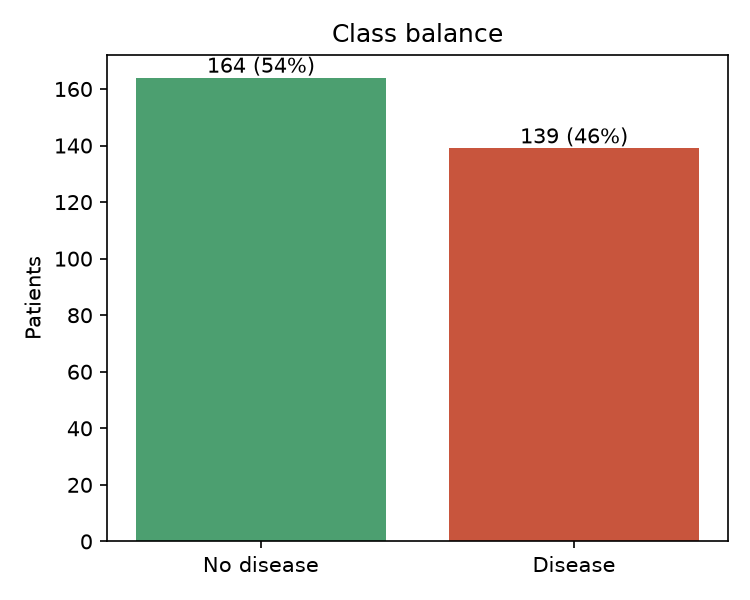

In [5]:
from src import eda
from IPython.display import Image
Image(eda.class_balance(df))

## Numeric features by outcome
Patients with disease have lower max heart rate (`thalach`) and higher ST depression (`oldpeak`).

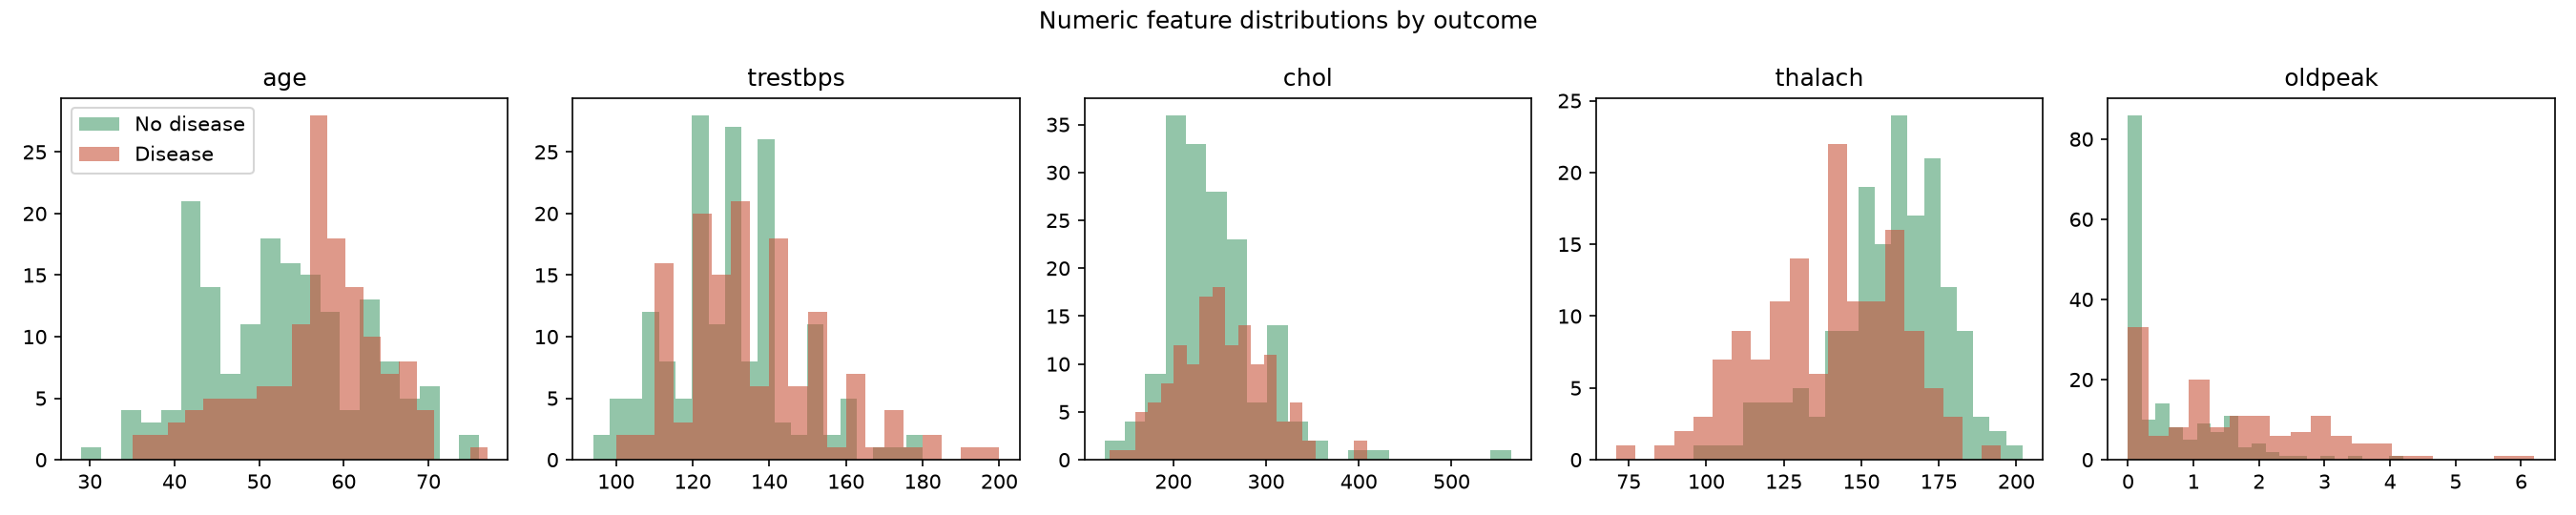

In [6]:
Image(eda.numeric_histograms(df))

## Categorical features – disease rate per level
Asymptomatic chest pain (`cp=4`), more coloured vessels (`ca`) and reversible defect (`thal=7`) carry strong signal. These are nominal codes, so they are one-hot encoded rather than treated as ordinal numbers.

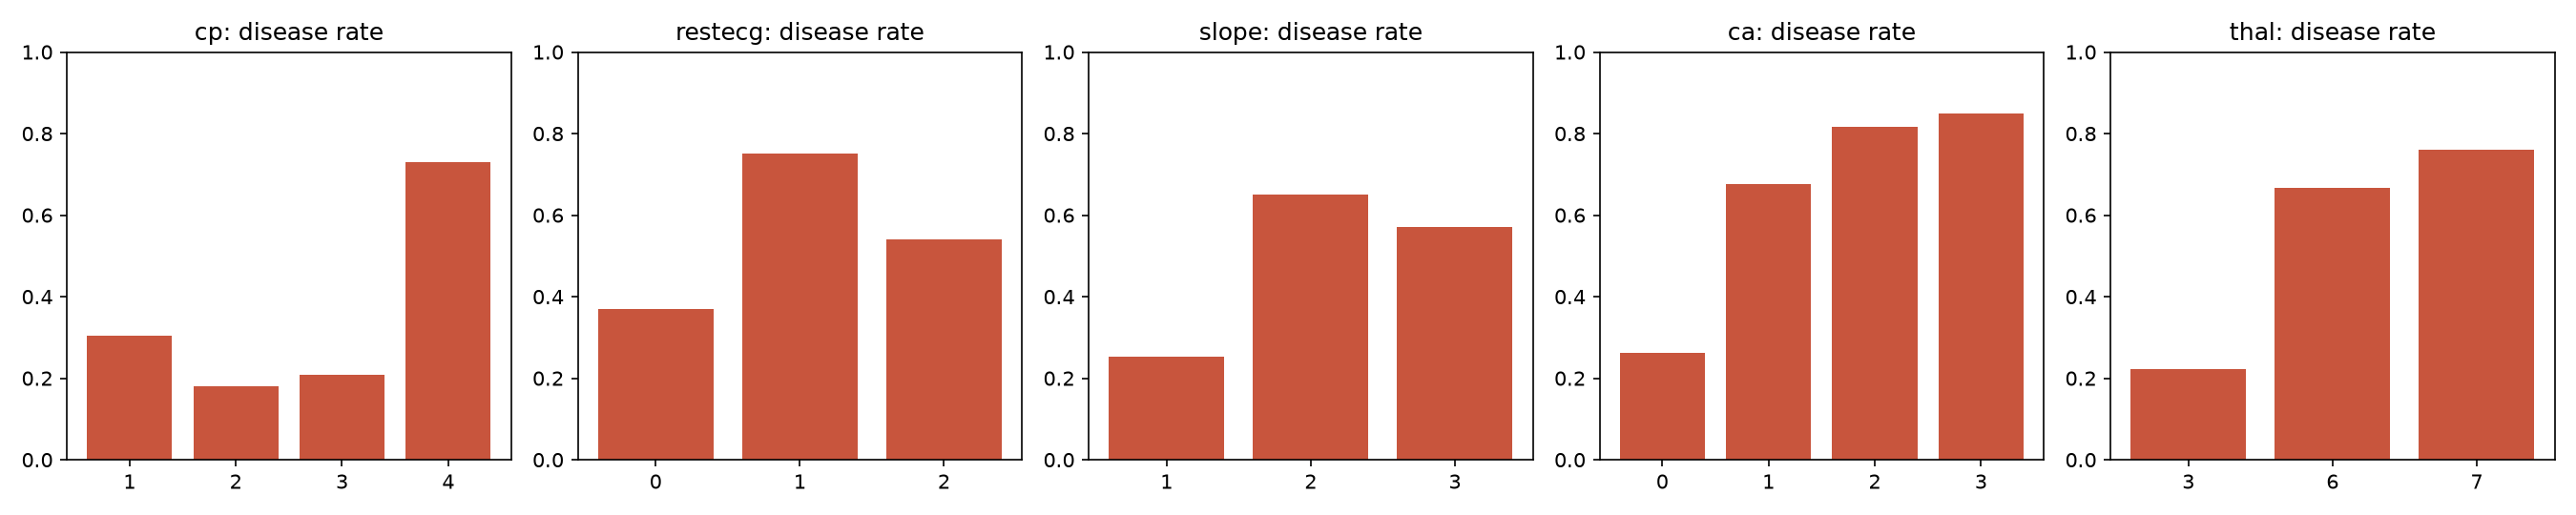

In [7]:
Image(eda.categorical_rates(df))

## Correlations

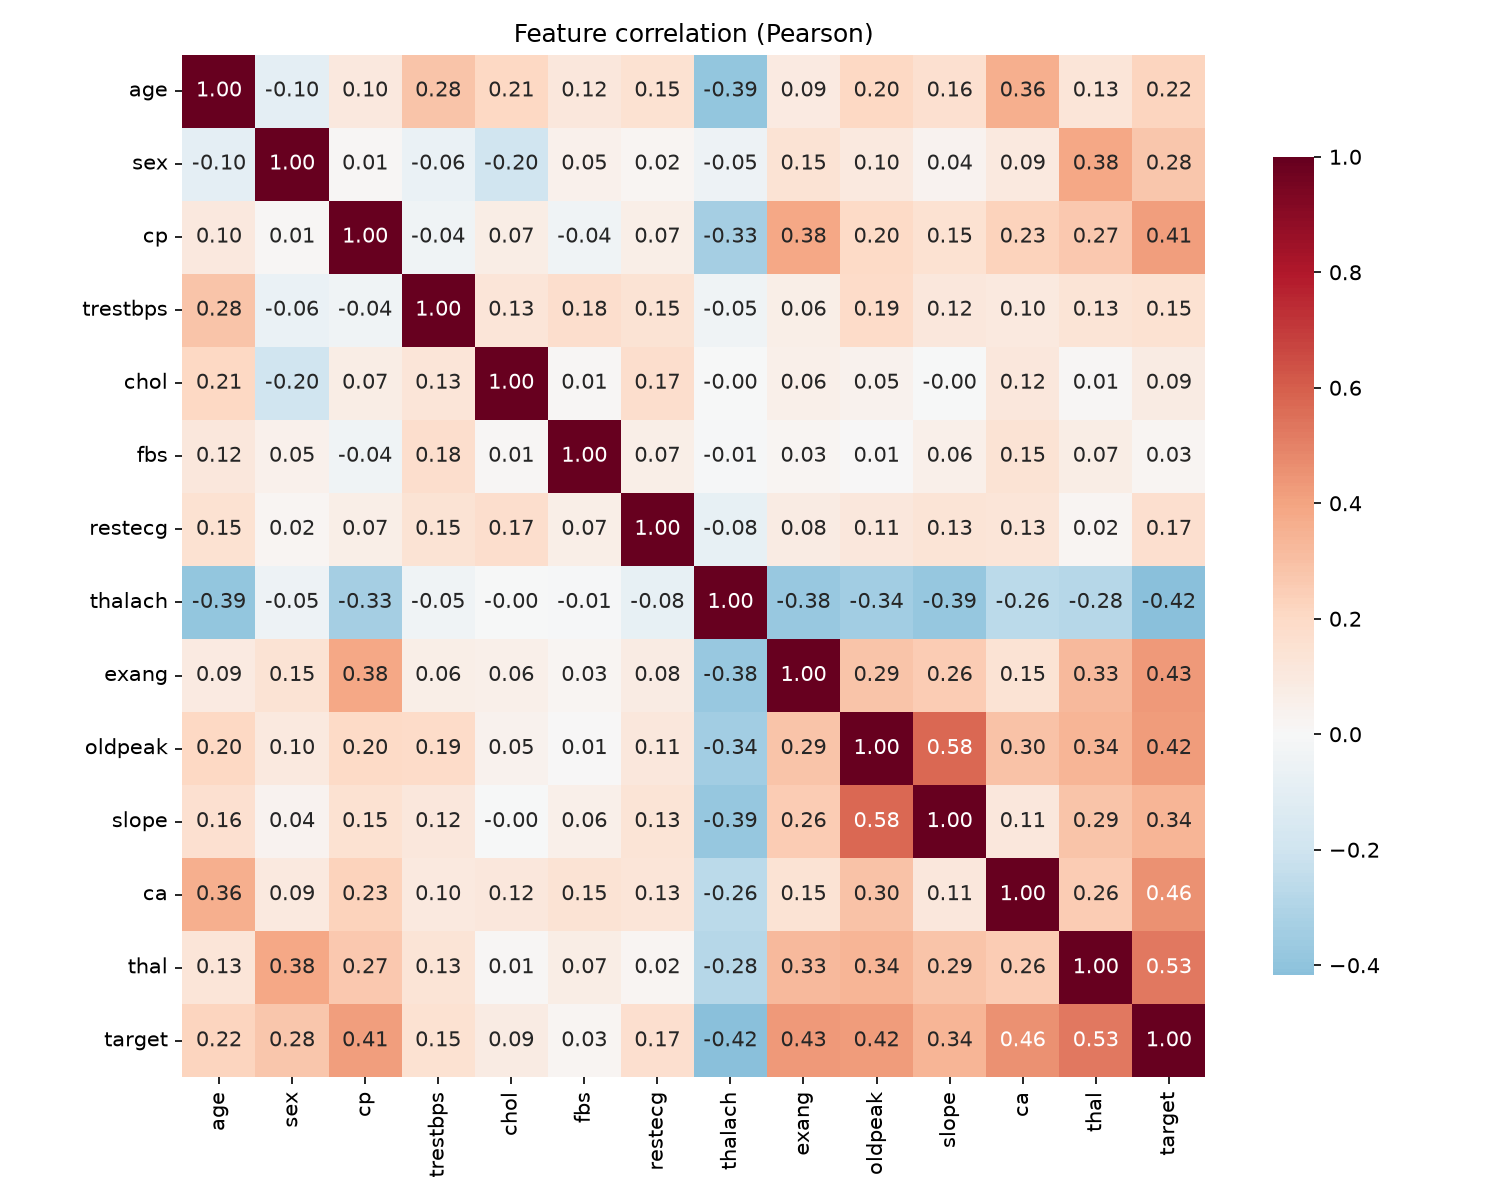

In [8]:
Image(eda.correlation_heatmap(df))

In [9]:
df.astype(float).corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3)

thal        0.526
ca          0.460
exang       0.432
oldpeak     0.425
thalach    -0.417
cp          0.414
slope       0.339
sex         0.277
age         0.223
restecg     0.169
trestbps    0.151
chol        0.085
fbs         0.025
Name: target, dtype: float64